# Cyclistic Bike-Share Case Study: Converting Casual Riders into Annual Members
**Google Data Analytics Professional Certificate, Capstone Case Study 1**

Data: Divvy trip data, November 2025 to October 2026 (12 months, 6.29 million trips)
Tools: Python (pandas, NumPy, matplotlib), Tableau Public

The analysis follows the six phases of the data analysis process:

| Phase | Content | Deliverable |
|---|---|---|
| 1. Ask | Business task, stakeholders, success criteria | Statement of the business task |
| 2. Prepare | Data source, ROCCC assessment, file-level profiling | Description of data sources |
| 3. Process | Combining, quality checks, cleaning log, feature engineering | Documentation of cleaning |
| 4. Analyze | Ride length, timing, seasonality, bike type, stations, ride purpose, pricing | Summary of analysis |
| 5. Share | Comparison scorecard and key findings | Visualizations and key findings |
| 6. Act | Recommendations, digital media plan, KPIs, limitations | Top three recommendations |
| 7. Export | Aggregated tables for the Tableau dashboard | Tableau data source |

**Analytical choices**
- Trips with missing station names are kept. About one in five trips has no station name, and almost all of them are e-bikes parked outside a dock. Dropping them would bias the bike-type and ride-length results.
- Medians are reported alongside means, because ride length is heavily right-skewed.
- Casual rides are segmented by inferred purpose (commute-like, utility, leisure) to size the group of casual riders whose behaviour already resembles that of members.
- A break-even model based on published Divvy prices estimates how often a casual rider needs to ride for a membership to pay off.

---
## 0. Setup

**Project structure**
```
cyclistic-case-study/
├── cyclistic_case_study.ipynb
├── data/
│   ├── raw/          # 12 monthly CSV files (not tracked in Git)
│   └── processed/    # generated by this notebook
├── figures/          # exported charts
└── tableau/          # aggregated tables for Tableau
```

**Environment**
```bash
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install -r requirements.txt
```
Running the full notebook takes about two minutes and needs roughly 4 GB of free memory.

Note: the file published as `202501-divvy-tripdata.csv` actually contains January 2026 trips (verified in section 2.4) and was renamed to `202601-divvy-tripdata.csv`. All months in this analysis are derived from `started_at`, not from file names.

In [38]:
# 0.1 Imports and global settings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from pandas.api.types import union_categoricals

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Paths are relative to the folder that contains this notebook
PROJECT_DIR   = Path.cwd()
RAW_DIR       = PROJECT_DIR / 'data' / 'raw'
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'
FIG_DIR       = PROJECT_DIR / 'figures'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Analysis window: 12 complete months
WINDOW_START = pd.Timestamp('2025-11-01')
WINDOW_END   = pd.Timestamp('2026-11-01')   # exclusive

print('pandas', pd.__version__, '| raw data folder:', RAW_DIR.relative_to(PROJECT_DIR))

pandas 3.1.1 | raw data folder: data/raw


In [39]:
# 0.2 Chart style: members are always blue and casual riders always orange
COLORS = {'member': '#2a78d6', 'casual': '#eb6834'}
ORDER  = ['member', 'casual']
LABELS = {'member': 'Annual member', 'casual': 'Casual rider'}
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e6e5e1'

plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.dpi': 110, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.edgecolor': MUTED, 'axes.labelcolor': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'xtick.color': INK2, 'ytick.color': INK2, 'font.size': 10.5,
    'legend.frameon': False, 'lines.linewidth': 2,
})
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#f3f8fe', '#9ec5f4', '#2a78d6', '#104281', '#0d366b'])
DIV_CMAP = LinearSegmentedColormap.from_list('member_casual', [COLORS['member'], '#e4e3df', COLORS['casual']])

def savefig(fig, name):
    # Save each chart to figures/ for the README and slides
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')

def pct_axis(ax, axis='y', decimals=0):
    fmt = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(fmt)

---
## 1. Ask

### 1.1 Business task
Analyse how annual members and casual riders use Cyclistic bikes differently, identify which casual riders are most likely to convert and when and where they can be reached, and use these insights to support a digital marketing strategy that converts casual riders into annual members.

### 1.2 Context
- Cyclistic's finance analysts have concluded that annual members are more profitable than casual riders.
- The Director of Marketing, Lily Moreno, believes that maximising the number of annual members is key to future growth.
- Casual riders already know the brand and already use the service, so converting them should be cheaper than acquiring new customers.
- Three questions guide the programme: (1) How do annual members and casual riders use Cyclistic bikes differently? (2) Why would casual riders buy an annual membership? (3) How can Cyclistic use digital media to influence casual riders to become members? This analysis focuses on question 1 and also provides evidence for questions 2 and 3.

### 1.3 Stakeholders
| Stakeholder | Interest | Implication for the analysis |
|---|---|---|
| Lily Moreno, Director of Marketing | An actionable campaign | Recommendations specify audience, channel and timing |
| Cyclistic executive team | Evidence and return on investment | Every finding is quantified; assumptions and limitations are stated |
| Marketing analytics team | A reproducible method | Each cleaning step is logged and the code can be re-run end to end |

### 1.4 Success criteria
1. Quantify the differences between the two groups in ride length, timing, seasonality, bike type, location and ride purpose.
2. Estimate the share of casual riding that already resembles member behaviour.
3. Explain, with a price model, why a casual rider would buy a membership.
4. Deliver three recommendations, each with a measurable KPI.

---
## 2. Prepare

### 2.1 Data source
- **Source:** Divvy (Chicago's bike-share system, operated by Lyft) publishes trip data under the [Divvy Data License Agreement](https://divvybikes.com/data-license-agreement), made available by Motivate International Inc. Cyclistic is a fictional company, and the Divvy data stands in for its trip history.
- **Scope:** 12 monthly CSV files, November 2025 to October 2026. One row represents one trip.
- **Fields:** `ride_id`, `rideable_type`, start and end timestamps, start and end station names and IDs, start and end coordinates, and `member_casual`.

### 2.2 ROCCC assessment
| Criterion | Assessment |
|---|---|
| Reliable | Yes. These are first-party operational records covering every trip, not a sample. |
| Original | Yes. The data is published directly by the operator. |
| Comprehensive | Partly. Trip behaviour is complete, but there is no rider ID, pass type, price paid, demographics or weather. |
| Current | Yes. The data covers the most recent 12 months. |
| Cited | Yes. The data is published with a licence. |

### 2.3 Privacy and limitations
- The data contains no personally identifiable information. Results are therefore at **trip level**: the data shows how many trips casual riders took, but not how many casual riders there are.
- Single-ride and day-pass purchases cannot be distinguished, and neither can residents and visitors.
- These gaps become the data requests in section 6.

### 2.4 File-level profiling
Before combining the files, each file is checked for consistent columns and for dates that match the month in its name.

In [40]:
# 2.4.1 List the raw files
files = sorted(RAW_DIR.glob('*-divvy-tripdata.csv'))
print(f'{len(files)} files found:')
for f in files:
    print(f'  {f.name:32s} {f.stat().st_size/1e6:8.1f} MB')
assert len(files) == 12, 'Expected 12 monthly files in data/raw/'

12 files found:
  202511-divvy-tripdata.csv            71.1 MB
  202512-divvy-tripdata.csv            28.3 MB
  202601-divvy-tripdata.csv            27.9 MB
  202602-divvy-tripdata.csv            41.2 MB
  202603-divvy-tripdata.csv            64.0 MB
  202604-divvy-tripdata.csv            89.8 MB
  202605-divvy-tripdata.csv           130.7 MB
  202606-divvy-tripdata.csv           152.6 MB
  202607-divvy-tripdata.csv           173.1 MB
  202608-divvy-tripdata.csv           172.8 MB
  202609-divvy-tripdata.csv           153.9 MB
  202610-divvy-tripdata.csv           154.4 MB


In [41]:
# 2.4.2 For each file: row count, column consistency and date range (reads only two columns)
expected_cols = None
profile = []
for f in files:
    cols = pd.read_csv(f, nrows=0).columns.tolist()
    if expected_cols is None:
        expected_cols = cols
    t = pd.read_csv(f, usecols=['ride_id', 'started_at'], dtype={'ride_id': 'string'}, parse_dates=['started_at'])
    profile.append({
        'file': f.name,
        'rows': len(t),
        'same_columns': cols == expected_cols,
        'first_start': t['started_at'].min(),
        'last_start': t['started_at'].max(),
        'main_month': t['started_at'].dt.to_period('M').mode()[0],
        'ride_id_lengths': sorted(t['ride_id'].str.len().unique().tolist()),
    })
file_profile = pd.DataFrame(profile)
file_profile

,file,rows,same_columns,first_start,last_start,main_month,ride_id_lengths
0,202511-divvy-tripdata.csv,356628,True,2025-10-31 01:24:38.549,2025-11-30 23:51:43.800,2025-11,[16]
1,202512-divvy-tripdata.csv,140534,True,2025-11-30 16:02:08.178,2025-12-31 23:53:24.274,2025-12,[16]
2,202601-divvy-tripdata.csv,137787,True,2025-12-31 10:30:49.482,2026-01-31 23:56:54.069,2026-01,[16]
3,202602-divvy-tripdata.csv,201450,True,2026-01-31 11:08:07.830,2026-02-28 23:57:54.093,2026-02,[16]
4,202603-divvy-tripdata.csv,317037,True,2026-02-28 10:48:22.074,2026-03-31 23:55:56.848,2026-03,[16]
5,202604-divvy-tripdata.csv,448252,True,2026-04-01 00:01:42.066,2026-04-30 23:58:56.151,2026-04,[16]
6,202605-divvy-tripdata.csv,653704,True,2026-04-30 00:24:47.685,2026-05-31 23:57:08.778,2026-05,[16]
7,202606-divvy-tripdata.csv,762550,True,2026-05-31 01:07:54.969,2026-06-30 23:58:47.113,2026-06,[16]
8,202607-divvy-tripdata.csv,869051,True,2026-06-29 23:11:19.957,2026-07-31 23:58:05.898,2026-07,[16]
9,202608-divvy-tripdata.csv,868191,True,2026-07-30 23:01:41.716,2026-08-31 23:55:36.979,2026-08,[16]


**Observations**
- `same_columns` is True for every file, so the files can be stacked directly.
- `main_month` confirms the month each file actually covers. The file originally named `202501` contains January 2026 trips.
- Each file starts slightly before the first of the month. Divvy files trips by end date, so trips that cross midnight at month end appear in the following file. The analysis window is therefore defined on `started_at`.
- In October 2026, `ride_id` changed from a 16-character hexadecimal string to a numeric ID. Reading the column as a string prevents pandas from converting it to an integer and losing precision.

---
## 3. Process

### 3.1 Tool choice
- **Python and pandas.** At 6.3 million rows, the data exceeds Excel's limit of 1,048,576 rows, and code makes every step reproducible and auditable.
- **Memory.** Repetitive text columns (station names, bike type, rider type) are stored as `category`, which reduces memory use from about 3 GB to about 0.5 GB.

### 3.2 Combine the 12 files

In [42]:
# 3.2 Read and combine
DTYPES = {
    'ride_id': 'string',            # must stay a string (see 2.4)
    'rideable_type': 'category',
    'start_station_name': 'category', 'start_station_id': 'category',
    'end_station_name': 'category',   'end_station_id': 'category',
    'member_casual': 'category',
}
CAT_COLS = [c for c, t in DTYPES.items() if t == 'category']

frames = []
for f in files:
    t = pd.read_csv(f, dtype=DTYPES, parse_dates=['started_at', 'ended_at'])
    frames.append(t)

# Each file has its own set of categories. Concatenating them directly would fall back to
# the object dtype and use far more memory, so the categories are unified first.
for c in CAT_COLS:
    all_cats = union_categoricals([t[c] for t in frames]).categories
    for t in frames:
        t[c] = t[c].cat.set_categories(all_cats)

df_raw = pd.concat(frames, ignore_index=True)
del frames

print(f'Combined: {len(df_raw):,} rows x {df_raw.shape[1]} columns')
print(f'Sum of file row counts: {file_profile.rows.sum():,} -> match: {len(df_raw) == file_profile.rows.sum()}')
print(f'Memory usage: {df_raw.memory_usage(deep=True).sum()/1e9:.2f} GB')
df_raw.info()

Combined: 6,294,451 rows x 13 columns
Sum of file row counts: 6,294,451 -> match: True
Memory usage: 0.52 GB
<class 'pandas.DataFrame'>
RangeIndex: 6294451 entries, 0 to 6294450
Data columns (total 13 columns):
 #   Column              Dtype         
---  ------              -----         
 0   ride_id             string        
 1   rideable_type       category      
 2   started_at          datetime64[us]
 3   ended_at            datetime64[us]
 4   start_station_name  category      
 5   start_station_id    category      
 6   end_station_name    category      
 7   end_station_id      category      
 8   start_lat           float64       
 9   start_lng           float64       
 10  end_lat             float64       
 11  end_lng             float64       
 12  member_casual       category      
dtypes: category(6), datetime64[us](2), float64(4), string(1)
memory usage: 494.8 MB


In [43]:
df_raw.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E555D9F8E9C2F56B,electric_bike,2025-11-04 00:09:07.792,2025-11-04 00:15:04.661,NaN,NaN,NaN,NaN,41.94,-87.67,41.94,-87.67,casual
1,EAEBE70DBF015886,electric_bike,2025-11-04 14:32:09.067,2025-11-04 14:36:43.998,NaN,NaN,NaN,NaN,41.90,-87.64,41.91,-87.64,casual
2,A42F8404F804E56E,electric_bike,2025-11-04 12:20:48.215,2025-11-04 12:21:01.630,NaN,NaN,NaN,NaN,41.89,-87.63,41.89,-87.63,casual
3,E49D01E38A1E074E,electric_bike,2025-11-04 12:17:16.548,2025-11-04 12:17:51.527,NaN,NaN,NaN,NaN,41.89,-87.63,41.89,-87.63,casual
4,9308F609195D2414,electric_bike,2025-11-04 08:16:27.979,2025-11-04 08:21:02.780,NaN,NaN,NaN,NaN,41.89,-87.64,41.88,-87.64,casual


### 3.3 Data quality checks
All issues are quantified before any rows are removed.

In [44]:
# 3.3.1 Duplicates and missing values
print('Duplicate ride_id values:', df_raw['ride_id'].duplicated().sum())
missing = (df_raw.isna().mean() * 100).round(2).rename('% missing').to_frame()
missing['count'] = df_raw.isna().sum()
missing[missing['count'] > 0]

Duplicate ride_id values: 35


,% missing,count
start_station_name,20.68,1301806
start_station_id,20.68,1301806
end_station_name,21.73,1367998
end_station_id,21.73,1367998
end_lat,0.08,5303
end_lng,0.08,5303


In [45]:
# 3.3.2 Which trips are missing a start station name?
miss_by_type = (df_raw.assign(missing_start_station=df_raw['start_station_name'].isna())
                .groupby(['rideable_type', 'member_casual'], observed=True)['missing_start_station']
                .mean().unstack().round(3))
miss_by_type

member_casual,casual,member
rideable_type,,
classic_bike,0.00,0.00
electric_bike,0.28,0.29


**Missing station names are not random.**
- Classic bikes have **no** missing station names, because they must be returned to a dock.
- About **29%** of e-bike trips have no station name, because e-bikes can be locked outside a station. Their coordinates are also rounded to two decimal places (roughly 1 km).

Missing station names therefore describe a real way of using the service rather than bad data. Dropping these rows would remove about 1.3 million trips, almost all of them e-bike trips, and would distort the bike-type and ride-length comparisons.

**Decision:** keep these rows. They are excluded only from station-level analysis, and distance and speed are calculated only for trips with precise station coordinates.

In [46]:
# 3.3.3 Ride length anomalies and operational stations
dur = (df_raw['ended_at'] - df_raw['started_at']).dt.total_seconds() / 60
print(dur.describe(percentiles=[.001, .01, .5, .99, .999]).round(2))
print('\nRide length < 0 min: ', (dur < 0).sum())
print('Ride length < 1 min: ', (dur < 1).sum())
print('Ride length > 24 h:  ', (dur > 24 * 60).sum())

# Stations named test, depot or warehouse are operational locations, not customer trips
stations = pd.Series(df_raw['start_station_name'].cat.categories)
print('\nStations to review:', stations[stations.str.contains('test|depot|warehouse|scooters classic', case=False)].tolist())

count   6,294,451.00
mean           15.07
std            49.95
min           -54.79
0.1%            0.03
1%              0.25
50%             9.20
99%            80.52
99.9%       1,001.00
max         1,559.95
dtype: float64

Ride length < 0 min:  29
Ride length < 1 min:  159672
Ride length > 24 h:   5155

Stations to review: ['Hastings St Depot LWS', 'Hubbard St Depot', 'SCOOTERS CLASSIC - 2132 W Hubbard ST', 'Hastings St Depot Public Rack', 'Hubbard St Depot Public Rack', 'STAFF & VISITORS @ West Chicago Warehouse', 'Hastings Test Station']


### 3.4 Cleaning rules
Each rule has a stated reason, and the number of rows it removes is logged.

| # | Rule | Reason |
|---|---|---|
| 1 | Remove duplicate `ride_id` values | `ride_id` must be unique. There are 35 duplicates, which are trips that appear in two adjacent monthly files. |
| 2 | Keep trips that started between 2025-11-01 and 2026-10-31 | This gives a consistent 12-month window. |
| 3 | Remove trips with no end coordinates | These are usually bikes that were not returned properly, and their distance cannot be calculated. |
| 4 | Remove trips that start or end at test, warehouse or depot stations | These are operational movements, not customer trips. Stations named *Public Rack* are public parking points and are kept. |
| 5 | Remove trips shorter than 1 minute, including negative durations | These are false starts, immediate re-docks or clock errors. Divvy applies the same 60-second threshold in its own reporting. |
| 6 | Remove trips longer than 24 hours | These are mostly unreturned bikes or system errors, and they would heavily distort averages. |
| – | Keep trips with missing station names | See 3.3.2. |

In [47]:
# 3.4 Apply the cleaning rules and build the cleaning log
OPS_STATIONS = ['Hastings Test Station', 'Hastings St Depot LWS', 'Hubbard St Depot',
                'SCOOTERS CLASSIC - 2132 W Hubbard ST', 'STAFF & VISITORS @ West Chicago Warehouse']

cleaning_log = []
def apply_step(data, mask_keep, step):
    before = len(data)
    data = data.loc[mask_keep]
    cleaning_log.append({'step': step, 'rows_before': before,
                         'rows_removed': before - len(data), 'rows_after': len(data)})
    return data

df = df_raw.copy()
df['ride_length_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

df = apply_step(df, ~df['ride_id'].duplicated(), '1. Duplicate ride_id')
df = apply_step(df, df['started_at'].between(WINDOW_START, WINDOW_END, inclusive='left'), '2. Outside 12-month window')
df = apply_step(df, df['end_lat'].notna() & df['end_lng'].notna(), '3. Missing end coordinates')
df = apply_step(df, ~(df['start_station_name'].isin(OPS_STATIONS) | df['end_station_name'].isin(OPS_STATIONS)), '4. Test / depot stations')
df = apply_step(df, df['ride_length_min'] >= 1, '5. Ride length < 1 min')
df = apply_step(df, df['ride_length_min'] <= 24 * 60, '6. Ride length > 24 h')
df = df.reset_index(drop=True)

log = pd.DataFrame(cleaning_log)
log['% of raw'] = log['rows_removed'] / len(df_raw) * 100
print(f'Rows kept: {len(df):,} ({len(df)/len(df_raw):.1%} of raw data)')
log

Rows kept: 6,128,724 (97.4% of raw data)


,step,rows_before,rows_removed,rows_after,% of raw
0,1. Duplicate ride_id,6294451,35,6294416,0.00
1,2. Outside 12-month window,6294416,128,6294288,0.00
2,3. Missing end coordinates,6294288,5279,6289009,0.08
3,4. Test / depot stations,6289009,450,6288559,0.01
4,5. Ride length < 1 min,6288559,159667,6128892,2.54
5,6. Ride length > 24 h,6128892,168,6128724,0.00


In [48]:
# 3.4.1 Check that cleaning did not remove one rider type disproportionately
removed_mix = pd.concat({
    'raw':   df_raw['member_casual'].value_counts(normalize=True),
    'clean': df['member_casual'].value_counts(normalize=True),
}, axis=1).round(4)
removed_mix

,raw,clean
member_casual,,
member,0.64,0.65
casual,0.36,0.35


The member/casual mix is almost identical before and after cleaning, so the cleaning rules did not introduce a bias between the two groups.

### 3.5 Feature engineering
The raw data contains only timestamps and coordinates. The following fields are derived to answer the business questions:

| Field | Definition | Question it answers |
|---|---|---|
| `ride_length_min` | Trip duration in minutes | How long? |
| `month`, `season` | Month and meteorological season of the start time | When in the year? (campaign timing) |
| `day_of_week`, `is_weekend` | Weekday of the start time | Commuting or weekend leisure? |
| `hour`, `time_of_day` | Start hour and time band | Peak hours? |
| `is_round_trip` | Start station equals end station | A strong signal of leisure riding |
| `distance_km` | Haversine distance between start and end | How far? |
| `speed_kmh` | Straight-line distance divided by duration | Travelling or browsing? |
| `has_station_info` | Both station names are present | Which rows are usable for station and distance analysis |

In [49]:
# 3.5 Feature engineering
def haversine_km(lat1, lon1, lat2, lon2):
    # Great-circle distance in km, vectorised over the whole column
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

DOW_ORDER   = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
MONTH_ORDER = pd.period_range('2025-11', '2026-10', freq='M').strftime('%Y-%m').tolist()
SEASON_MAP  = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
               6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Fall', 10: 'Fall', 11: 'Fall'}

s = df['started_at']
df['date']        = s.dt.normalize()
df['month']       = pd.Categorical(s.dt.strftime('%Y-%m'), categories=MONTH_ORDER, ordered=True)
df['season']      = pd.Categorical(s.dt.month.map(SEASON_MAP), categories=['Spring', 'Summer', 'Fall', 'Winter'], ordered=True)
df['day_of_week'] = pd.Categorical(s.dt.strftime('%a'), categories=DOW_ORDER, ordered=True)
df['is_weekend']  = s.dt.day_of_week >= 5
df['hour']        = s.dt.hour.astype('int8')
df['time_of_day'] = pd.cut(df['hour'], bins=[-1, 5, 9, 15, 19, 23],
                           labels=['Night (0-5)', 'AM peak (6-9)', 'Midday (10-15)', 'PM peak (16-19)', 'Evening (20-23)'])

df['has_station_info'] = df['start_station_name'].notna() & df['end_station_name'].notna()
df['is_round_trip']    = df['has_station_info'] & (df['start_station_name'].astype(str) == df['end_station_name'].astype(str))
df['distance_km']      = haversine_km(df['start_lat'], df['start_lng'], df['end_lat'], df['end_lng']).astype('float32')
df['speed_kmh']        = (df['distance_km'] / (df['ride_length_min'] / 60)).astype('float32')

df[['started_at', 'member_casual', 'rideable_type', 'ride_length_min', 'month', 'day_of_week',
    'hour', 'time_of_day', 'is_round_trip', 'distance_km', 'speed_kmh']].sample(5, random_state=1)

,started_at,member_casual,rideable_type,ride_length_min,month,day_of_week,hour,time_of_day,is_round_trip,distance_km,speed_kmh
4672542,2026-09-13 11:34:03.971,casual,electric_bike,7.38,2026-09,Sun,11,Midday (10-15),False,1.28,10.42
5638220,2026-10-05 18:52:55.567,casual,classic_bike,8.99,2026-10,Mon,18,PM peak (16-19),False,1.25,8.35
1133675,2026-04-15 16:31:48.957,casual,electric_bike,3.67,2026-04,Wed,16,PM peak (16-19),False,0.00,0.00
3338971,2026-07-30 08:56:47.393,member,classic_bike,2.12,2026-07,Thu,8,AM peak (6-9),False,0.27,7.69
4817931,2026-09-16 00:42:37.657,casual,electric_bike,9.95,2026-09,Wed,0,Night (0-5),False,3.38,20.40


In [50]:
# 3.6 Save the clean data. Parquet is about 5x smaller and 10x faster to read than CSV.
# To resume later without re-running sections 2-3: df = pd.read_parquet(PROCESSED_DIR / 'trips_clean.parquet')
df.to_parquet(PROCESSED_DIR / 'trips_clean.parquet', index=False)
log.to_csv(PROCESSED_DIR / 'cleaning_log.csv', index=False)
del df_raw
print('Saved:', (PROCESSED_DIR / 'trips_clean.parquet').relative_to(PROJECT_DIR))

Saved: data/processed/trips_clean.parquet


---
## 4. Analyze

The analysis starts with overall volume and then works through ride length, timing, bike type, location and inferred purpose. It ends with a price model that addresses why a casual rider would buy a membership.

Because members take almost twice as many trips as casual riders, comparisons of shape use **shares within each group** (for example, the percentage of casual trips that start on a Saturday) rather than raw counts.

### 4.1 Overall volume

In [51]:
# 4.1 Ride volume and share
overview = (df.groupby('member_casual', observed=True)
              .agg(rides=('ride_id', 'size'),
                   median_min=('ride_length_min', 'median'),
                   mean_min=('ride_length_min', 'mean'),
                   total_hours=('ride_length_min', lambda x: x.sum() / 60))
              .reindex(ORDER))
overview['share_of_rides'] = overview['rides'] / overview['rides'].sum()
overview['share_of_ride_time'] = overview['total_hours'] / overview['total_hours'].sum()
overview

,rides,median_min,mean_min,total_hours,share_of_rides,share_of_ride_time
member_casual,,,,,,
member,3967086,8.68,12.11,"800,948.30",0.65,0.55
casual,2161638,11.09,17.97,"647,508.55",0.35,0.45


**Finding 4.1: Casual riders take 35% of trips but account for 45% of total ride time.**
- After cleaning there are about 6.13 million trips: 3.97 million by members (65%) and 2.16 million by casual riders (35%).
- Measured by total ride time, casual riders account for 45%, because their trips are longer.
- These are trip counts, not rider counts. Casual riders almost certainly take fewer trips per person than members, so there are likely far more casual riders than the trip share suggests. That cannot be verified with this data (see section 6).

### 4.2 Ride length

In [52]:
# 4.2.1 Ride length statistics: medians and percentiles, not only means
dur_stats = (df.groupby('member_casual', observed=True)['ride_length_min']
               .describe(percentiles=[.25, .5, .75, .9]).reindex(ORDER))
dur_stats['share_>30min'] = df.groupby('member_casual', observed=True)['ride_length_min'].apply(lambda x: (x > 30).mean())
dur_stats['share_>45min'] = df.groupby('member_casual', observed=True)['ride_length_min'].apply(lambda x: (x > 45).mean())
dur_stats[['count', 'mean', '25%', '50%', '75%', '90%', 'share_>30min', 'share_>45min']]

,count,mean,25%,50%,75%,90%,share_>30min,share_>45min
member_casual,,,,,,,,
member,"3,967,086.00",12.11,5.19,8.68,14.61,23.36,0.05,0.02
casual,"2,161,638.00",17.97,6.46,11.09,19.84,35.42,0.13,0.07


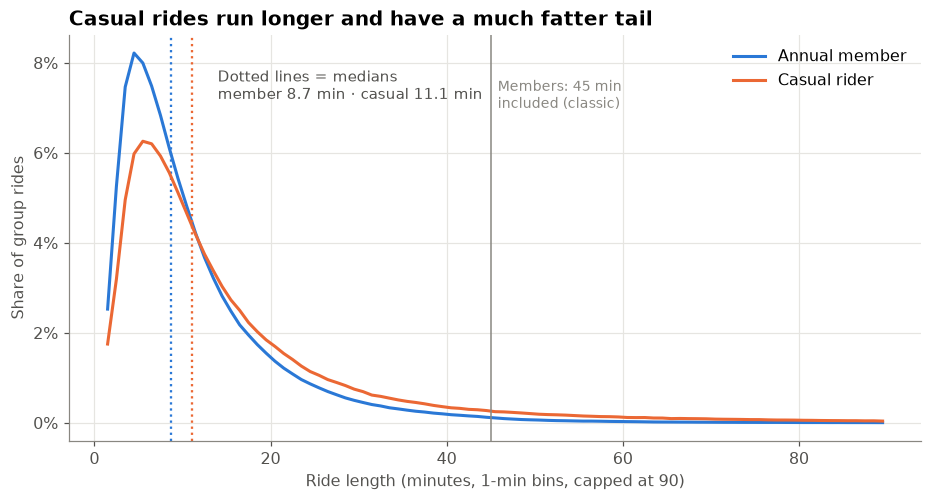

In [53]:
# 4.2.2 Ride length distribution: 1-minute bins, share of each group's trips
bins = np.arange(1, 91, 1)
fig, ax = plt.subplots(figsize=(10, 4.8))
for g in ORDER:
    x = df.loc[df['member_casual'] == g, 'ride_length_min']
    h, edges = np.histogram(x, bins=bins)
    ax.plot(edges[:-1] + 0.5, h / len(x), color=COLORS[g], label=LABELS[g])
    med = x.median()
    ax.axvline(med, color=COLORS[g], ls=':', lw=1.5)
ax.axvline(45, color=MUTED, lw=1)
ax.text(45.8, 0.07, 'Members: 45 min\nincluded (classic)', color=MUTED, fontsize=9)
meds = df.groupby('member_casual', observed=True)['ride_length_min'].median()
ax.text(14, 0.072, f"Dotted lines = medians\nmember {meds['member']:.1f} min · casual {meds['casual']:.1f} min",
        color=INK2, fontsize=9.5)
pct_axis(ax, decimals=0)
ax.set(xlabel='Ride length (minutes, 1-min bins, capped at 90)', ylabel='Share of group rides',
       title='Casual rides run longer and have a much fatter tail')
ax.legend()
savefig(fig, '01_ride_length_distribution'); plt.show()

**Finding 4.2: Casual riders ride longer, and many more of their trips are very long.**
- Median ride length is 11.1 minutes for casual riders and 8.7 minutes for members (28% longer). The means (18.0 and 12.1 minutes) are pulled up by a small number of very long trips, which is why medians are used in the rest of the analysis.
- 13% of casual trips last more than 30 minutes, compared with 5% of member trips (2.4 times as many). Above 45 minutes the figures are about 7% and 2%.
- The member distribution flattens out around 45 minutes, which matches the 45 minutes of classic-bike riding included in the membership.

**Implication:** casual riders pay by the minute and ride longer, so they are the most exposed to price. The saving a membership offers on the same trip is a direct conversion message (quantified in 4.9).

### 4.3 Distance and speed

In [54]:
# 4.3 Distance and speed: station-to-station trips only, excluding round trips (straight-line distance ~ 0)
ab = df[df['has_station_info'] & ~df['is_round_trip']]
dist_speed = (ab.groupby('member_casual', observed=True)
                .agg(rides=('ride_id', 'size'),
                     median_distance_km=('distance_km', 'median'),
                     median_minutes=('ride_length_min', 'median'),
                     median_speed_kmh=('speed_kmh', 'median'))
                .reindex(ORDER))
round_trip = (df[df['has_station_info']].groupby('member_casual', observed=True)['is_round_trip'].mean()
                .reindex(ORDER).rename('round_trip_share'))
dist_speed.join(round_trip)

,rides,median_distance_km,median_minutes,median_speed_kmh,round_trip_share
member_casual,,,,,
member,2648738,1.63,8.63,12.14,0.02
casual,1324317,1.79,11.76,10.47,0.07


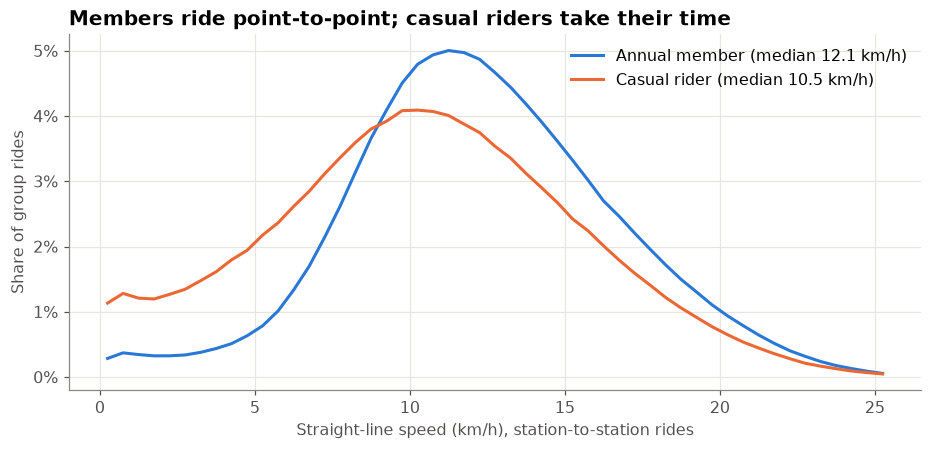

In [55]:
# 4.3.1 Straight-line speed distribution (km/h)
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.arange(0, 26, 0.5)
for g in ORDER:
    x = ab.loc[ab['member_casual'] == g, 'speed_kmh']
    h, edges = np.histogram(x, bins=bins)
    ax.plot(edges[:-1] + 0.25, h / len(x), color=COLORS[g], label=f"{LABELS[g]} (median {x.median():.1f} km/h)")
pct_axis(ax, decimals=0)
ax.set(xlabel='Straight-line speed (km/h), station-to-station rides', ylabel='Share of group rides',
       title='Members ride point-to-point; casual riders take their time')
ax.legend()
savefig(fig, '02_speed_distribution'); plt.show()

**Finding 4.3: Casual riders do not ride farther; they ride more slowly.**
- Straight-line distances on station-to-station trips are almost the same: median 1.8 km for casual riders and 1.6 km for members.
- Casual trips take longer (11.8 against 8.6 minutes), so their median speed is lower (10.5 against 12.1 km/h). The casual speed distribution also has a long tail below 5 km/h, consistent with stopping and sightseeing.
- Round trips (same start and end station) make up 7.4% of casual trips and 2.2% of member trips, 3.3 times as many.

**Implication:** members use the bikes as transport. Many casual riders use them as an experience. Even so, the typical casual trip covers the same short distance as a member trip, which suggests that a large share of casual riding is practical, everyday travel. Section 4.8 sizes this group.

### 4.4 Day of week and hour of day

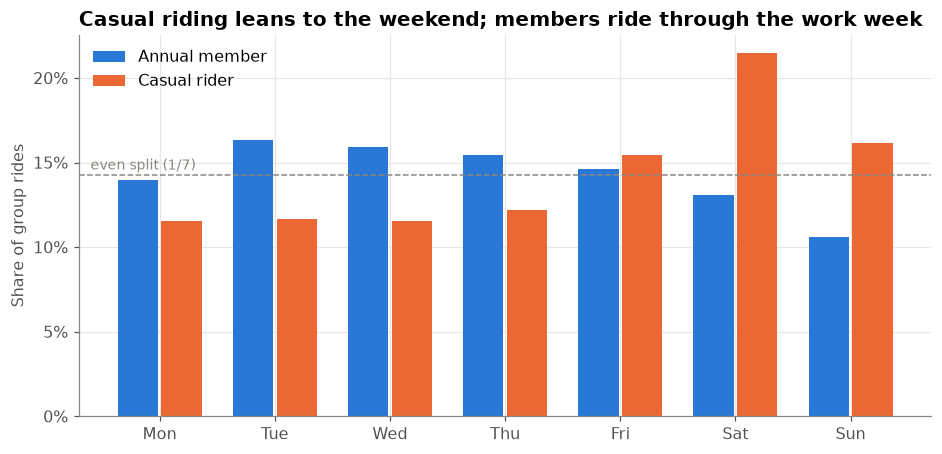

Weekend share of trips:
member_casual
member    23.7%
casual    37.6%
Name: is_weekend, dtype: str


In [56]:
# 4.4.1 Day of week (share of each group's trips)
dow = (df.groupby(['member_casual', 'day_of_week'], observed=True).size()
         .unstack(0)[ORDER])
dow_share = dow / dow.sum()

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(DOW_ORDER)); w = 0.38
for i, g in enumerate(ORDER):
    ax.bar(x + (i - 0.5) * w, dow_share[g], width=w - 0.03, color=COLORS[g], label=LABELS[g])
ax.axhline(1 / 7, color=MUTED, lw=1, ls='--'); ax.text(-0.6, 1 / 7 + 0.003, 'even split (1/7)', color=MUTED, fontsize=9)
ax.set_xticks(x, DOW_ORDER); pct_axis(ax)
ax.set(ylabel='Share of group rides', title='Casual riding leans to the weekend; members ride through the work week')
ax.legend(loc='upper left')
savefig(fig, '03_day_of_week'); plt.show()

weekend_share = df.groupby('member_casual', observed=True)['is_weekend'].mean().reindex(ORDER)
print('Weekend share of trips:'); print(weekend_share.map('{:.1%}'.format))

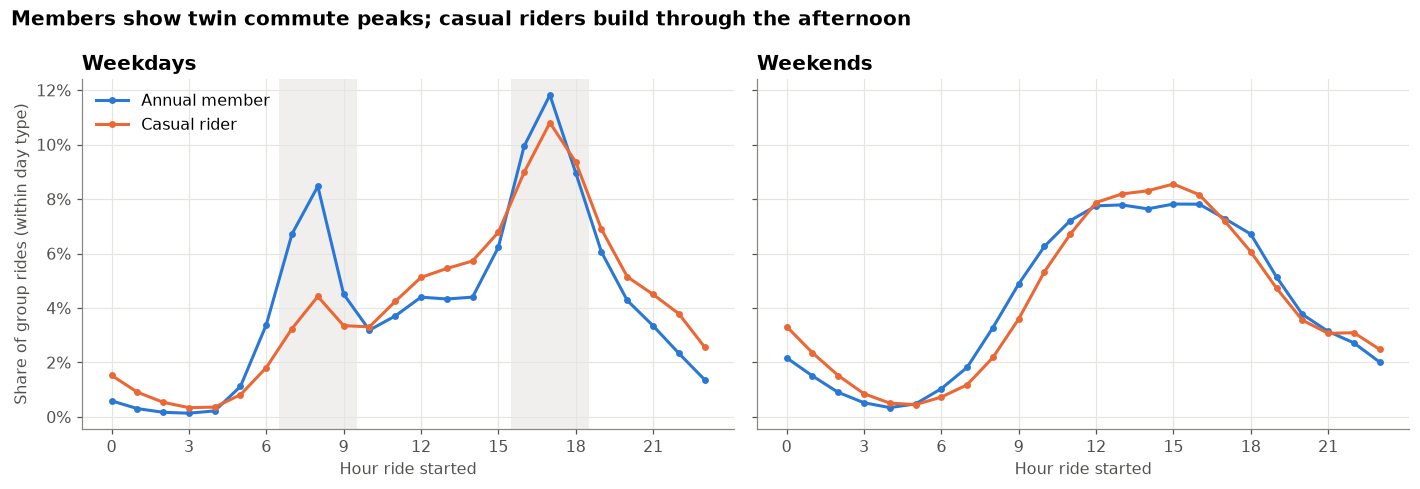

In [57]:
# 4.4.2 Hour of day: weekdays and weekends
hourly = (df.groupby(['is_weekend', 'member_casual', 'hour'], observed=True).size()
            .groupby(level=[0, 1], observed=True).transform(lambda x: x / x.sum()))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, wk, title in zip(axes, [False, True], ['Weekdays', 'Weekends']):
    for g in ORDER:
        y = hourly.loc[(wk, g)]
        ax.plot(y.index, y.values, color=COLORS[g], label=LABELS[g], marker='o', ms=3.5)
    ax.set_xticks(range(0, 24, 3)); ax.set(xlabel='Hour ride started', title=title)
    if not wk:
        for h0, h1 in [(7, 9), (16, 18)]:
            ax.axvspan(h0 - 0.5, h1 + 0.5, color=GRID, alpha=0.6, lw=0)
axes[0].set_ylabel('Share of group rides (within day type)'); pct_axis(axes[0])
axes[0].legend(loc='upper left')
fig.suptitle('Members show twin commute peaks; casual riders build through the afternoon', x=0.01, ha='left',
             fontweight='bold', fontsize=13)
fig.tight_layout()
savefig(fig, '04_hour_of_day'); plt.show()

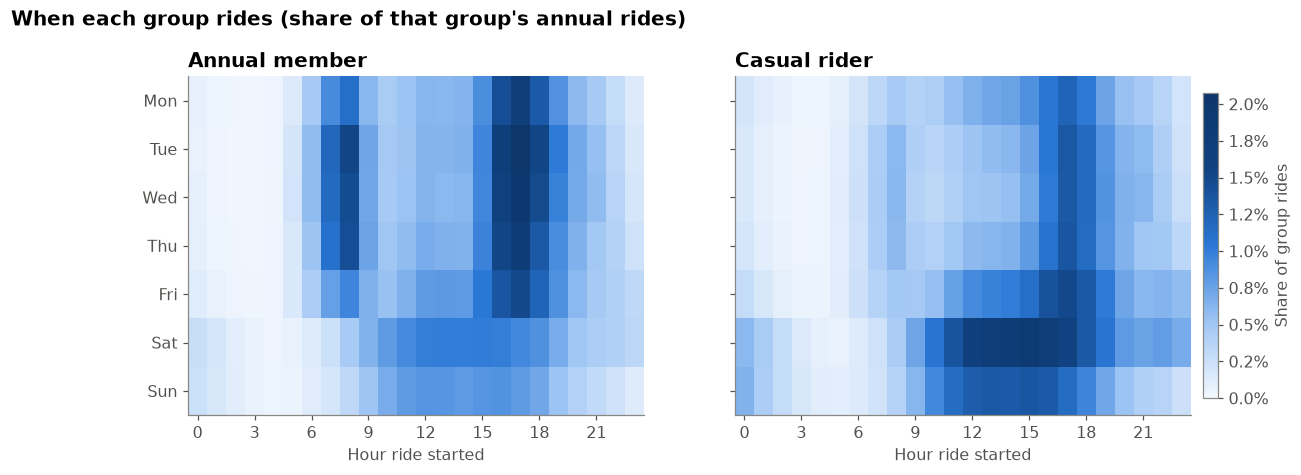

In [58]:
# 4.4.3 Heatmap: day of week x hour (share of each group's trips, shared colour scale)
heat = {g: (df[df['member_casual'] == g].groupby(['day_of_week', 'hour'], observed=True).size()
              .unstack().reindex(DOW_ORDER)) for g in ORDER}
heat = {g: h / h.values.sum() for g, h in heat.items()}
vmax = max(h.values.max() for h in heat.values())

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, g in zip(axes, ORDER):
    im = ax.imshow(heat[g].values, aspect='auto', cmap=SEQ_CMAP, vmin=0, vmax=vmax)
    ax.set_yticks(range(7), DOW_ORDER); ax.set_xticks(range(0, 24, 3), range(0, 24, 3))
    ax.set(title=LABELS[g], xlabel='Hour ride started'); ax.grid(False)
cb = fig.colorbar(im, ax=axes, shrink=0.9, pad=0.01); cb.ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, 1))
cb.set_label('Share of group rides')
fig.suptitle('When each group rides (share of that group\'s annual rides)', x=0.01, y=1.03, ha='left', fontweight='bold', fontsize=13)
savefig(fig, '05_heatmap_dow_hour'); plt.show()

**Finding 4.4: Members ride to a commuting rhythm, while casual riders favour weekends and afternoons. Casual riders also have a clear weekday evening peak.**
- **Day of week:** 38% of casual trips happen at the weekend, compared with 24% of member trips. Saturday is the busiest casual day (about 21% of casual trips). Member riding peaks from Tuesday to Thursday.
- **Weekday hours:** members show a clear double peak at 8 am and 5 pm. The casual morning peak is about half the member peak, but the **casual 5 pm peak is almost as high as the member peak**.
- **Weekend hours:** the two curves almost overlap. At weekends, members ride for leisure too.
- **Heatmap:** member riding concentrates in two vertical bands on weekdays. Casual riding concentrates in a block from 10 am to 6 pm on Saturday and Sunday, plus 4 to 6 pm on weekdays.

**Implications**
1. The weekday evening peak shows that many casual riders already ride home from work or to evening plans. They are one habit away from member-style use: riding the morning leg as well.
2. The best times to reach them are weekdays from 4 to 7 pm (ride-home messages) and weekend middays and afternoons (lakefront leisure).

### 4.5 Seasonality

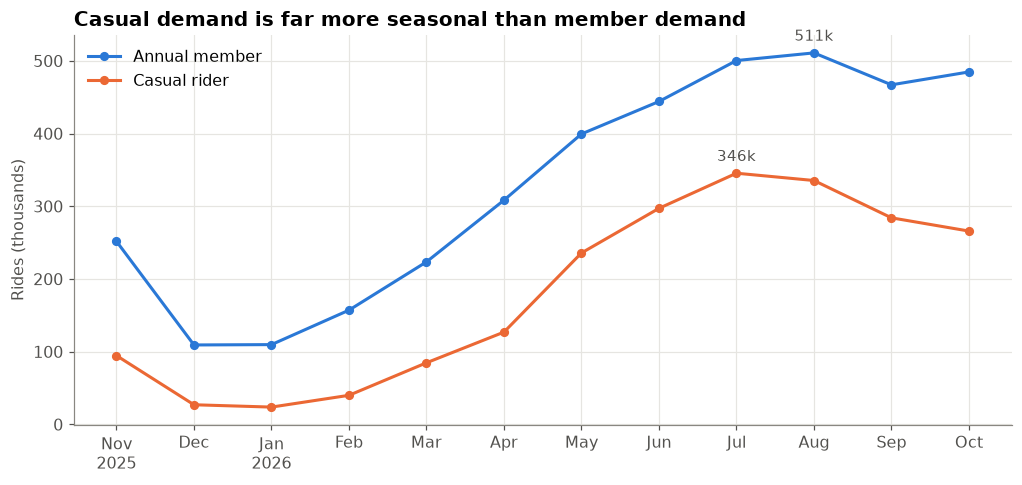

member_casual,member,casual,casual_share,casual_index_vs_jan,member_index_vs_jan
month,,,,,
2025-11,251824,94683,0.27,3.97,2.29
2025-12,109318,27082,0.20,1.13,1.00
2026-01,109795,23874,0.18,1.00,1.00
2026-02,157175,40068,0.20,1.68,1.43
2026-03,223572,84791,0.27,3.55,2.04
2026-04,308432,127006,0.29,5.32,2.81
2026-05,399500,235844,0.37,9.88,3.64
2026-06,444142,297199,0.40,12.45,4.05
2026-07,500453,345514,0.41,14.47,4.56


In [59]:
# 4.5.1 Monthly trips
monthly = df.groupby(['month', 'member_casual'], observed=True).size().unstack()[ORDER]
fig, ax = plt.subplots(figsize=(11, 4.6))
for g in ORDER:
    ax.plot(MONTH_ORDER, monthly[g] / 1000, color=COLORS[g], marker='o', ms=5, label=LABELS[g])
    ax.annotate(f'{monthly[g].max()/1000:,.0f}k', xy=(monthly[g].idxmax(), monthly[g].max() / 1000),
                xytext=(0, 8), textcoords='offset points', ha='center', color=INK2, fontsize=9.5)
ax.set(ylabel='Rides (thousands)', title='Casual demand is far more seasonal than member demand')
ax.set_xticks(range(12), [pd.Period(m).strftime('%b\n%Y') if m in ('2025-11', '2026-01') else pd.Period(m).strftime('%b') for m in MONTH_ORDER])
ax.legend(loc='upper left')
savefig(fig, '06_monthly_rides'); plt.show()

monthly_tbl = monthly.copy()
monthly_tbl['casual_share'] = monthly['casual'] / monthly.sum(axis=1)
monthly_tbl['casual_index_vs_jan'] = monthly['casual'] / monthly.loc['2026-01', 'casual']
monthly_tbl['member_index_vs_jan'] = monthly['member'] / monthly.loc['2026-01', 'member']
monthly_tbl

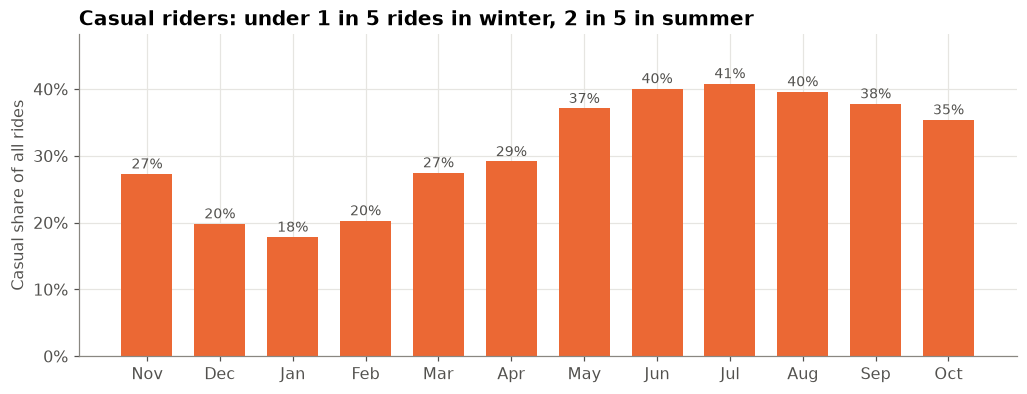

In [60]:
# 4.5.2 Casual share of all trips by month (separate chart rather than a second y-axis)
fig, ax = plt.subplots(figsize=(11, 3.8))
share = monthly_tbl['casual_share']
ax.bar(range(12), share, color=COLORS['casual'], width=0.7)
for i, v in enumerate(share):
    ax.text(i, v + 0.008, f'{v:.0%}', ha='center', color=INK2, fontsize=9)
ax.set_xticks(range(12), [pd.Period(m).strftime('%b') for m in MONTH_ORDER]); pct_axis(ax)
ax.set(ylabel='Casual share of all rides', ylim=(0, share.max() * 1.18),
       title='Casual riders: under 1 in 5 rides in winter, 2 in 5 in summer')
savefig(fig, '07_casual_share_by_month'); plt.show()

**Finding 4.5: Casual demand is far more seasonal than member demand.**
- Casual trips peak at about 346,000 in July, 14.5 times the January level (about 24,000). Member trips rise only 4.6 times over the same period.
- The casual share of all trips rises from 18% in January to 41% in July.
- Casual trips almost double from April to May (127,000 to 236,000), the fastest growth of the year, and stay high in September and October (between 260,000 and 285,000).

**Implications for campaign timing**
- **March to May is the main conversion window.** Casual riders are returning in large numbers, and a membership bought then covers the whole riding season.
- **June to August offers the most reach.** This is the time for broad awareness and on-street media, with messages about the savings available for the rest of the season.
- **November to February is not worth conversion spend.** Casual volume is low, and the feeling that a membership would go unused in winter is the strongest objection.

### 4.6 Bike type

In [61]:
# 4.6 Bike type mix and median ride length by bike type
bike = pd.crosstab(df['member_casual'], df['rideable_type'], normalize='index').reindex(ORDER)
bike_dur = df.pivot_table(index='member_casual', columns='rideable_type', values='ride_length_min',
                          aggfunc='median', observed=True).reindex(ORDER)
display(bike.style.format('{:.1%}').set_caption('Bike type share (by row)'))
display(bike_dur.style.format('{:.1f} min').set_caption('Median ride length by bike type'))

# E-bike share within each ride length band
df['length_band'] = pd.cut(df['ride_length_min'], [0, 10, 20, 30, 45, 60, 1440],
                           labels=['<10', '10-20', '20-30', '30-45', '45-60', '60+'])
eb = (df.assign(is_ebike=df['rideable_type'] == 'electric_bike')
        .pivot_table(index='length_band', columns='member_casual', values='is_ebike', aggfunc='mean', observed=True)[ORDER])
eb.style.format('{:.1%}').set_caption('E-bike share by ride length band')

rideable_type,classic_bike,electric_bike
member_casual,,
member,30.8%,69.2%
casual,24.6%,75.4%


rideable_type,classic_bike,electric_bike
member_casual,,
member,9.2 min,8.5 min
casual,15.5 min,10.1 min


member_casual,member,casual
length_band,,
<10,70.9%,83.2%
10-20,70.5%,75.7%
20-30,63.3%,68.6%
30-45,51.0%,61.2%
45-60,56.6%,55.7%
60+,66.0%,41.2%


**Finding 4.6: Both groups ride mostly e-bikes, and casual riders even more so.**
- E-bikes account for 75% of casual trips and 69% of member trips.
- On classic bikes, casual riders' median ride length is 15.5 minutes, against 9.2 minutes for members. Casual riders on classic bikes are mostly leisure riders.
- About 83% of casual trips shorter than 10 minutes are on e-bikes.

**Implication:** at 2026 Divvy prices, casual riders pay $0.44 per minute on an e-bike and members pay $0.20, so **members ride e-bikes for less than half price**. Because casual riders use e-bikes so heavily, e-bike pricing is a more persuasive message for most of them than the 45 minutes of free classic riding.

### 4.7 Stations

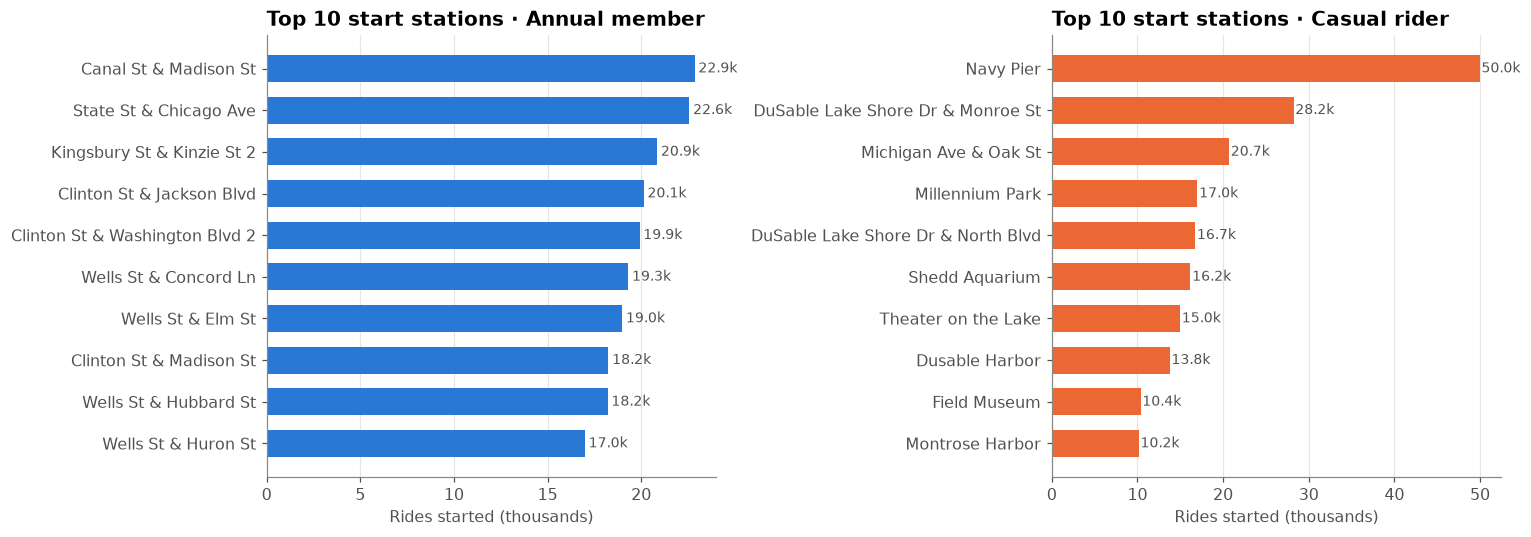

In [62]:
# 4.7.1 Top 10 start stations for each group
st = df[df['start_station_name'].notna()]
top = {g: st[st['member_casual'] == g]['start_station_name'].value_counts().head(10) for g in ORDER}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, g in zip(axes, ORDER):
    s_ = top[g].iloc[::-1]
    ax.barh(s_.index.astype(str), s_.values / 1000, color=COLORS[g], height=0.65)
    for i, v in enumerate(s_.values):
        ax.text(v / 1000 + 0.2, i, f'{v/1000:.1f}k', va='center', color=INK2, fontsize=9)
    ax.set(title=f'Top 10 start stations · {LABELS[g]}', xlabel='Rides started (thousands)')
    ax.grid(axis='y', visible=False)
fig.tight_layout()
savefig(fig, '08_top_stations'); plt.show()

Stations with at least 2,000 starts: 545; network-wide casual share: 35.3%


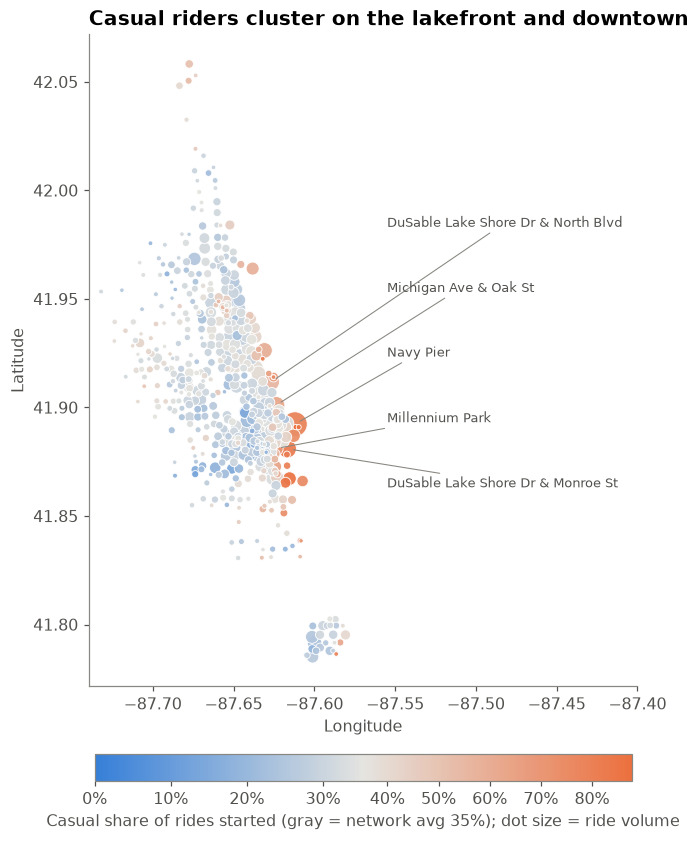

In [63]:
# 4.7.2 Station profile: casual share of trips started (stations with at least 2,000 starts)
station = (st.groupby('start_station_name', observed=True)
             .agg(rides=('ride_id', 'size'),
                  casual_share=('member_casual', lambda x: (x == 'casual').mean()),
                  lat=('start_lat', 'median'), lng=('start_lng', 'median'),
                  round_trip_share=('is_round_trip', 'mean'))
             .query('rides >= 2000')
             .sort_values('rides', ascending=False))
overall_casual = (df['member_casual'] == 'casual').mean()
print(f'Stations with at least 2,000 starts: {len(station)}; network-wide casual share: {overall_casual:.1%}')

fig, ax = plt.subplots(figsize=(9, 10))
norm = TwoSlopeNorm(vmin=0, vcenter=overall_casual, vmax=station['casual_share'].max())
sc = ax.scatter(station['lng'], station['lat'], s=station['rides'] / 250, c=station['casual_share'],
                cmap=DIV_CMAP, norm=norm, edgecolor='white', linewidth=0.6, alpha=0.95)
cb = fig.colorbar(sc, ax=ax, orientation='horizontal', shrink=0.7, pad=0.08); cb.ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, 0))
cb.set_label(f'Casual share of rides started (gray = network avg {overall_casual:.0%}); dot size = ride volume')
# Label the five stations with the most casual trips; labels sit in the right margin with leader lines
lab = station.assign(casual_rides=station['rides'] * station['casual_share']).nlargest(5, 'casual_rides').sort_values('lat', ascending=False)
for k, (name, r) in enumerate(lab.iterrows()):
    ax.annotate(name, (r['lng'], r['lat']), xytext=(-87.555, 41.985 - k * 0.03), textcoords='data',
                fontsize=8.5, color=INK2, va='center',
                arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.7, shrinkA=0, shrinkB=4))
ax.set_xlim(right=-87.40)
ax.set(title='Casual riders cluster on the lakefront and downtown',
       xlabel='Longitude', ylabel='Latitude'); ax.set_aspect(1 / np.cos(np.radians(41.9)))
ax.grid(False)
savefig(fig, '09_station_map'); plt.show()

In [64]:
# 4.7.3 High-volume stations where casual riders are the majority (candidates for on-street and geo-targeted media)
casual_hotspots = station[station['casual_share'] >= 0.5].sort_values('rides', ascending=False)
share_of_casual_starts = (st['start_station_name'].isin(casual_hotspots.index) & (st['member_casual'] == 'casual')).sum() \
                         / (st['member_casual'] == 'casual').sum()
print(f'Stations with casual share >= 50%: {len(casual_hotspots)}, '
      f'accounting for {share_of_casual_starts:.1%} of casual trips that start at a station')
casual_hotspots.head(15)[['rides', 'casual_share', 'round_trip_share']]

Stations with casual share >= 50%: 40, accounting for 17.6% of casual trips that start at a station


,rides,casual_share,round_trip_share
start_station_name,,,
Navy Pier,65922,0.76,0.15
DuSable Lake Shore Dr & Monroe St,36030,0.78,0.16
Michigan Ave & Oak St,34253,0.60,0.11
DuSable Lake Shore Dr & North Blvd,30820,0.54,0.05
Theater on the Lake,26239,0.57,0.06
Millennium Park,25504,0.67,0.09
Shedd Aquarium,19794,0.82,0.09
Dusable Harbor,19198,0.72,0.13
Montrose Harbor,18155,0.56,0.11


**Finding 4.7: Casual riding concentrates on the lakefront; member riding concentrates in the Loop and West Loop.**
- The top casual start stations are almost all on the lakefront or at attractions: Navy Pier (about 50,000 casual starts, far ahead of any other), DuSable Lake Shore Drive, Millennium Park, Shedd Aquarium and the Field Museum.
- The top member start stations are in the Loop, West Loop and River North: Canal St & Madison St and the Clinton St stations near Union Station and Ogilvie, and the Wells St corridor.
- On the map, orange stations (high casual share) run along the lakefront. Blue stations (member-dominated) cluster in the West Loop and in Hyde Park around the University of Chicago.
- The 40 stations where casual riders are the majority account for about 18% of casual trips that start at a station, so casual riding is concentrated enough for on-street and geo-fenced media.

**Implication:** many casual riders at lakefront attractions are visitors who are unlikely to buy a Chicago membership; day passes serve them better. Stronger membership prospects are the casual riders in the commuter corridors (see table B in 4.8.3).

### 4.8 Ride purpose: segmenting casual riding

The analysis so far shows how casual riders differ from members. For marketing, the more useful question is how much casual riding **already looks like member riding**. These riders have the habit already and need only a reason to do the maths.

The data has no trip purpose field, so purpose is inferred with transparent rules:

| Segment | Rule | Interpretation |
|---|---|---|
| **Commute-like** | Weekday, start hour 6-9 or 16-19, 30 minutes or less, not a round trip | Travel to and from work or study |
| **Utility** | Other weekday hours, 30 minutes or less, not a round trip | Errands, appointments, lunch |
| **Leisure** | Weekend, or a round trip, or longer than 30 minutes | Recreation, sightseeing, exercise |

These rules infer purpose; they do not observe it. Their value lies in comparison, since the same rules are applied to both groups.

In [65]:
# 4.8.1 Label every trip
weekday = ~df['is_weekend']
peak_hour = df['hour'].between(6, 9) | df['hour'].between(16, 19)
short_ab = (df['ride_length_min'] <= 30) & ~df['is_round_trip']

df['ride_purpose'] = np.select(
    [weekday & peak_hour & short_ab, weekday & short_ab],
    ['Commute-like', 'Utility'], default='Leisure')
df['ride_purpose'] = pd.Categorical(df['ride_purpose'], ['Commute-like', 'Utility', 'Leisure'], ordered=True)

purpose = pd.crosstab(df['member_casual'], df['ride_purpose'], normalize='index').reindex(ORDER)
purpose_n = pd.crosstab(df['member_casual'], df['ride_purpose']).reindex(ORDER)
display(purpose.style.format('{:.1%}').set_caption('Ride purpose mix (share of each group)'))
purpose_n

ride_purpose,Commute-like,Utility,Leisure
member_casual,,,
member,43.3%,28.6%,28.2%
casual,27.1%,26.6%,46.3%


ride_purpose,Commute-like,Utility,Leisure
member_casual,,,
member,1716208,1134054,1116824
casual,585813,575210,1000615


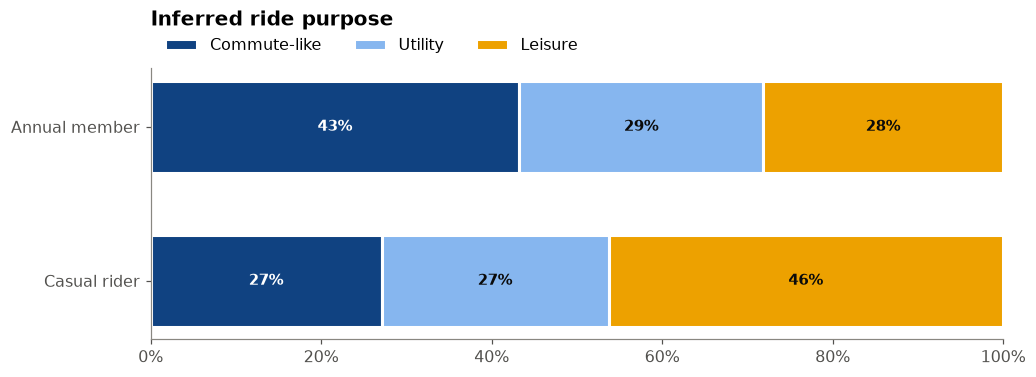

In [66]:
# 4.8.2 100% stacked bar chart
PURPOSE_COLORS = {'Commute-like': '#104281', 'Utility': '#86b6ef', 'Leisure': '#eda100'}
fig, ax = plt.subplots(figsize=(10, 3.2))
left = np.zeros(2)
for p in ['Commute-like', 'Utility', 'Leisure']:
    vals = purpose[p].values
    ax.barh([LABELS[g] for g in ORDER], vals, left=left, color=PURPOSE_COLORS[p], label=p,
            height=0.6, edgecolor='white', linewidth=2)
    for i, v in enumerate(vals):
        ax.text(left[i] + v / 2, i, f'{v:.0%}', ha='center', va='center',
                color='white' if p == 'Commute-like' else INK, fontsize=10, fontweight='bold')
    left += vals
ax.invert_yaxis(); pct_axis(ax, 'x'); ax.set_xlim(0, 1); ax.grid(False)
ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('Inferred ride purpose', pad=28)
savefig(fig, '10_ride_purpose'); plt.show()

In [67]:
# 4.8.3 Where do member-like casual trips start? Two kinds of target location.
member_like_casual = df[(df['member_casual'] == 'casual') & df['ride_purpose'].isin(['Commute-like', 'Utility'])]
print(f'Member-like casual trips: {len(member_like_casual):,} '
      f'({len(member_like_casual) / (df.member_casual == "casual").sum():.1%} of all casual trips)')
tgt = (member_like_casual.dropna(subset=['start_station_name'])
         .groupby('start_station_name', observed=True).size().rename('member_like_casual_rides').to_frame()
         .join(station[['casual_share', 'rides']], how='inner'))
# A: lakefront / attraction stations (casual share >= 50%)
# B: commuter-corridor stations (casual riders are a minority, mixed into member commuting flows)
tourist_hubs  = tgt[tgt['casual_share'] >= 0.5].nlargest(8, 'member_like_casual_rides')
commuter_hubs = tgt[tgt['casual_share'] < 0.5].nlargest(10, 'member_like_casual_rides')
display(tourist_hubs.style.format({'casual_share': '{:.0%}', 'member_like_casual_rides': '{:,}', 'rides': '{:,}'})
        .set_caption('A. Lakefront and attraction stations'))
commuter_hubs.style.format({'casual_share': '{:.0%}', 'member_like_casual_rides': '{:,}', 'rides': '{:,}'}) \
    .set_caption('B. Commuter-corridor stations (primary conversion targets)')

Member-like casual trips: 1,161,023 (53.7% of all casual trips)


,member_like_casual_rides,casual_share,rides
start_station_name,,,
Navy Pier,"15,395",76%,"65,922"
DuSable Lake Shore Dr & Monroe St,"8,070",78%,"36,030"
Michigan Ave & Oak St,"6,723",60%,"34,253"
DuSable Lake Shore Dr & North Blvd,"6,665",54%,"30,820"
Shedd Aquarium,"6,188",82%,"19,794"
Theater on the Lake,"5,699",57%,"26,239"
Millennium Park,"5,509",67%,"25,504"
Dusable Harbor,"4,585",72%,"19,198"


,member_like_casual_rides,casual_share,rides
start_station_name,,,
Wells St & Hubbard St,"5,403",31%,"26,329"
Wells St & Concord Ln,"5,070",33%,"28,667"
State St & Chicago Ave,"4,796",26%,"30,640"
Wells St & Huron St,"4,734",30%,"24,315"
Wells St & Elm St,"4,724",30%,"27,181"
Clinton St & Madison St,"4,550",27%,"24,865"
Canal St & Madison St,"4,450",22%,"29,200"
LaSalle St & Illinois St,"4,251",36%,"21,581"
Clark St & Armitage Ave,"4,232",38%,"24,357"


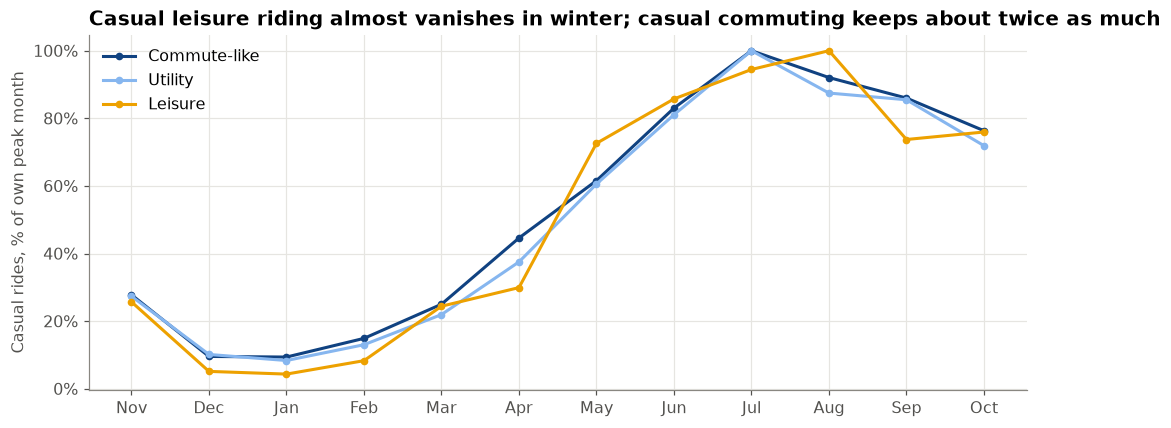

month,2026-01,2026-07,winter_vs_summer
ride_purpose,,,
Commute-like,8714,92966,0.09
Utility,7939,95111,0.08
Leisure,7221,157437,0.05


In [68]:
# 4.8.4 Seasonality of casual trips by purpose (each indexed to its own peak month)
mp = (df[df['member_casual'] == 'casual'].groupby(['month', 'ride_purpose'], observed=True).size()
        .unstack()[['Commute-like', 'Utility', 'Leisure']])
mp_idx = mp / mp.max()
fig, ax = plt.subplots(figsize=(11, 4.2))
for p in mp_idx.columns:
    ax.plot(range(12), mp_idx[p], color=PURPOSE_COLORS[p], marker='o', ms=4, label=p)
ax.set_xticks(range(12), [pd.Period(m).strftime('%b') for m in MONTH_ORDER]); pct_axis(ax)
ax.set(ylabel='Casual rides, % of own peak month', title='Casual leisure riding almost vanishes in winter; casual commuting keeps about twice as much')
ax.legend()
savefig(fig, '11_casual_purpose_seasonality'); plt.show()
(mp.loc[['2026-01', '2026-07']].T.assign(winter_vs_summer=lambda t: t['2026-01'] / t['2026-07']))

**Finding 4.8: More than half of casual trips already look like member trips.**
- Using the same rules for both groups: member trips are 43% commute-like, 29% utility and 28% leisure. Casual trips are 27% commute-like, 27% utility and 46% leisure.
- About **1.16 million casual trips (54% of casual riding)** are weekday, point-to-point trips of 30 minutes or less, with no meaningful difference from how members ride.
- These member-like casual trips start in two kinds of location:
  - **A. Lakefront and attraction stations** (Navy Pier, Lake Shore Drive). Some of these are likely weekday visitors whom the rules cannot separate from locals.
  - **B. Commuter-corridor stations** (Wells St corridor, State St & Chicago Ave, Clinton St and Canal St at Madison). Casual riders make up only 20-40% of trips here. Casual riders travelling within member commuting flows are almost certainly local, so this is the most reliable conversion audience.
- Seasonality: in January, casual commute-like trips are still about 9% of their July level, while leisure trips fall to about 5%. Practical casual riders are more resilient in winter and closer to member behaviour.

**Implication:** a single message for all casual riders would be inefficient. The first priority should be **member-like casual riders**, who already have the riding habit and need a clear financial reason to switch.

### 4.9 Why would a casual rider buy a membership? A break-even model

Cyclistic is fictional, so Divvy's published 2026 prices are used as assumptions (source: divvybikes.com/pricing and the Divvy Help Center, accessed November 2026). All prices are held in one dictionary and can be changed before re-running.

| Item | Casual rider (single ride) | Annual member |
|---|---|---|
| Annual fee | – | **$143.90** ($99 offer for new and lapsed members) |
| Classic bike | $1 unlock + $0.19/min | First 45 minutes included, then $0.20/min |
| E-bike | $1 unlock + $0.44/min | $0.20/min |
| Day pass | $18.10/day (classic rides up to 3 hours) | – |

For every casual trip, the model compares the single-ride price with the price the same trip would have cost a member. The difference is the saving a membership would have delivered.

In [69]:
# 4.9.1 Price assumptions (editable)
PRICING = {
    'annual_fee': 143.90, 'annual_fee_promo': 99.00,
    'casual_unlock': 1.00, 'casual_classic_per_min': 0.19, 'casual_ebike_per_min': 0.44,
    'member_classic_included_min': 45, 'member_overage_per_min': 0.20, 'member_ebike_per_min': 0.20,
}

def casual_cost(minutes, bike):
    m = np.ceil(minutes)  # Divvy rounds up to the next minute
    rate = np.where(bike == 'electric_bike', PRICING['casual_ebike_per_min'], PRICING['casual_classic_per_min'])
    return PRICING['casual_unlock'] + m * rate

def member_cost(minutes, bike):
    m = np.ceil(minutes)
    classic = np.maximum(0, m - PRICING['member_classic_included_min']) * PRICING['member_overage_per_min']
    ebike = m * PRICING['member_ebike_per_min']
    return np.where(bike == 'electric_bike', ebike, classic)

cas = df[df['member_casual'] == 'casual'][['ride_length_min', 'rideable_type', 'ride_purpose']].copy()
bike_arr = cas['rideable_type'].astype(str).values
cas['cost_as_casual'] = casual_cost(cas['ride_length_min'].values, bike_arr)
cas['cost_as_member'] = member_cost(cas['ride_length_min'].values, bike_arr)
cas['saving'] = cas['cost_as_casual'] - cas['cost_as_member']

price_tbl = cas.groupby('ride_purpose', observed=True).agg(
    rides=('saving', 'size'), median_minutes=('ride_length_min', 'median'),
    avg_cost_as_casual=('cost_as_casual', 'mean'), avg_cost_as_member=('cost_as_member', 'mean'),
    avg_saving_per_ride=('saving', 'mean'))
price_tbl.loc['All casual rides'] = [len(cas), cas.ride_length_min.median(), cas.cost_as_casual.mean(),
                                     cas.cost_as_member.mean(), cas.saving.mean()]
price_tbl['rides'] = price_tbl['rides'].astype(int)
price_tbl['breakeven_rides_per_year'] = PRICING['annual_fee'] / price_tbl['avg_saving_per_ride']
price_tbl['breakeven_rides_per_month'] = price_tbl['breakeven_rides_per_year'] / 12
price_tbl['breakeven_rides_per_month_promo_99'] = PRICING['annual_fee_promo'] / price_tbl['avg_saving_per_ride'] / 12
price_tbl

,rides,median_minutes,avg_cost_as_casual,avg_cost_as_member,avg_saving_per_ride,breakeven_rides_per_year,breakeven_rides_per_month,breakeven_rides_per_month_promo_99
ride_purpose,,,,,,,,
Commute-like,585813,9.14,5.31,1.75,3.57,40.36,3.36,2.31
Utility,575210,9.27,5.37,1.75,3.61,39.82,3.32,2.28
Leisure,1000615,15.23,9.69,3.78,5.90,24.37,2.03,1.40
All casual rides,2161638,11.09,7.35,2.69,4.66,30.87,2.57,1.77


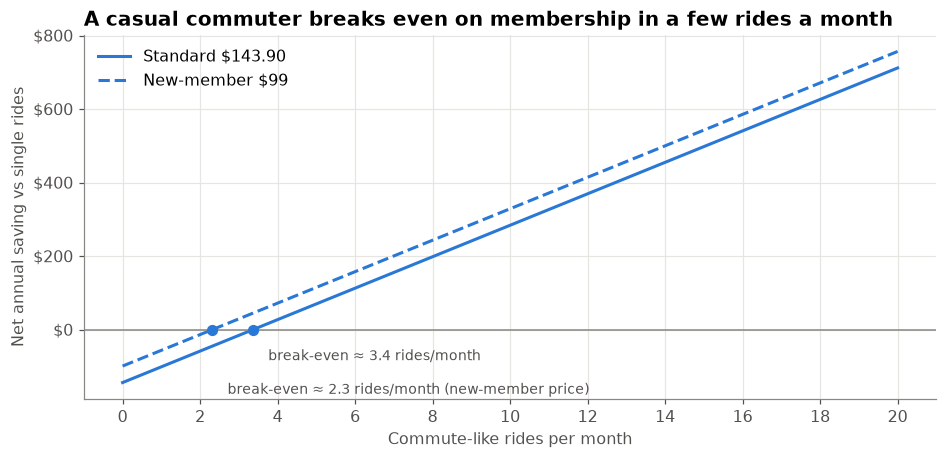

Average saving per commute-like casual trip: $3.57


In [70]:
# 4.9.2 Net annual saving by number of commute-like rides per month
saving_comm = price_tbl.loc['Commute-like', 'avg_saving_per_ride']
n = np.arange(0, 21)
fig, ax = plt.subplots(figsize=(10, 4.3))
for fee, ls, lab in [(PRICING['annual_fee'], '-', f"Standard ${PRICING['annual_fee']:.2f}"),
                     (PRICING['annual_fee_promo'], '--', f"New-member ${PRICING['annual_fee_promo']:.0f}")]:
    net = n * 12 * saving_comm - fee
    ax.plot(n, net, color=COLORS['member'], ls=ls, label=lab)
    be = fee / (12 * saving_comm)
    ax.scatter([be], [0], color=COLORS['member'], zorder=3, s=40)
    promo = fee < PRICING['annual_fee']
    ax.annotate(f'break-even ≈ {be:.1f} rides/month' + (' (new-member price)' if promo else ''), (be, 0),
                xytext=(10, -42 if promo else -20), textcoords='offset points', color=INK2, fontsize=9)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(range(0, 21, 2))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
ax.set(xlabel='Commute-like rides per month', ylabel='Net annual saving vs single rides',
       title='A casual commuter breaks even on membership in a few rides a month')
ax.legend(loc='upper left')
savefig(fig, '12_breakeven'); plt.show()
print(f'Average saving per commute-like casual trip: ${saving_comm:.2f}')

**Finding 4.9: A casual commuter breaks even on a membership at about 3.4 rides a month.**
- At single-ride prices, the average casual trip costs about **$7.35**. The same trip would cost a member about **$2.69**.
- For commute-like casual trips, the average saving is about **$3.57 per trip**. At the standard $143.90 fee, a membership pays for itself after about **40 trips a year, or 3.4 a month**. At the $99 new-member price, the break-even point falls to about **2.3 trips a month**.
- In other words, **less than one round-trip commute a week** makes a membership cheaper than single rides.
- Leisure trips save more per trip ($5.90, because they are longer), but leisure riders include many visitors who ride infrequently. A large saving per trip does not by itself make a membership attractive.

**Assumptions:** every casual trip is priced as a single ride (in practice, some casual riders buy day passes). Taxes and the member e-bike cap for 30-45 minute trips are not modelled. All prices can be changed in `PRICING` and should be checked against Cyclistic's actual price list with the finance team.

---
## 5. Share

### 5.1 Member and casual comparison scorecard

In [71]:
# 5.1 Scorecard of the key metrics
g = df.groupby('member_casual', observed=True)
scorecard = pd.DataFrame({
    'Share of rides':               g.size() / len(df),
    'Median ride (min)':            g['ride_length_min'].median(),
    'Rides > 30 min':               g['ride_length_min'].apply(lambda x: (x > 30).mean()),
    'Weekend share':                g['is_weekend'].mean(),
    'Weekday AM/PM peak share':     g.apply(lambda x: ((~x.is_weekend) & (x.hour.between(6, 9) | x.hour.between(16, 19))).mean(), include_groups=False),
    'Round-trip share (station)':   df[df.has_station_info].groupby('member_casual', observed=True)['is_round_trip'].mean(),
    'Median speed km/h (A→B)':      ab.groupby('member_casual', observed=True)['speed_kmh'].median(),
    'E-bike share':                 g['rideable_type'].apply(lambda x: (x == 'electric_bike').mean()),
    'Summer (Jun–Aug) share':       g['season'].apply(lambda x: (x == 'Summer').mean()),
    'Winter (Dec–Feb) share':       g['season'].apply(lambda x: (x == 'Winter').mean()),
    'Commute-like + utility share': purpose[['Commute-like', 'Utility']].sum(axis=1),
}).T[ORDER]
scorecard['casual vs member'] = scorecard['casual'] / scorecard['member']

# Formatted copy for display; the numeric scorecard is kept for export
num_rows = ['Median ride (min)', 'Median speed km/h (A→B)']
show = scorecard.copy().astype(object)
for r in scorecard.index:
    for c in ORDER:
        show.loc[r, c] = f'{scorecard.loc[r, c]:.1f}' if r in num_rows else f'{scorecard.loc[r, c]:.1%}'
    show.loc[r, 'casual vs member'] = f"{scorecard.loc[r, 'casual vs member']:.2f}x"
show

member_casual,member,casual,casual vs member
Share of rides,64.7%,35.3%,0.54x
Median ride (min),8.7,11.1,1.28x
Rides > 30 min,5.4%,13.2%,2.45x
Weekend share,23.7%,37.6%,1.59x
Weekday AM/PM peak share,45.7%,30.5%,0.67x
Round-trip share (station),2.2%,7.4%,3.34x
Median speed km/h (A→B),12.1,10.5,0.86x
E-bike share,69.2%,75.4%,1.09x
Summer (Jun–Aug) share,36.7%,45.3%,1.23x
Winter (Dec–Feb) share,9.5%,4.2%,0.44x


In [72]:
# 5.2 Export summary tables
scorecard.to_csv(PROCESSED_DIR / 'scorecard.csv')
monthly_tbl.to_csv(PROCESSED_DIR / 'monthly_summary.csv')
station.to_csv(PROCESSED_DIR / 'station_summary.csv')
price_tbl.to_csv(PROCESSED_DIR / 'breakeven_by_purpose.csv')
print('Charts:', sorted(p.name for p in FIG_DIR.glob('*.png')))

Charts: ['01_ride_length_distribution.png', '02_speed_distribution.png', '03_day_of_week.png', '04_hour_of_day.png', '05_heatmap_dow_hour.png', '06_monthly_rides.png', '07_casual_share_by_month.png', '08_top_stations.png', '09_station_map.png', '10_ride_purpose.png', '11_casual_purpose_seasonality.png', '12_breakeven.png']


### 5.3 Executive summary

**Question:** How do annual members and casual riders use Cyclistic differently, and which casual riders are worth converting?

**Answer, based on 6.13 million trips from November 2025 to October 2026:**

| # | Dimension | Annual members | Casual riders | Insight |
|---|---|---|---|---|
| 1 | Ride length | Median 8.7 min | Median 11.1 min; 2.4x the share of trips over 30 min | Casual riders pay by the minute and ride longer, so they are the most price-sensitive |
| 2 | Riding style | 12.1 km/h, point-to-point | 10.5 km/h; 3.3x the share of round trips | Members travel; many casual riders explore |
| 3 | Timing | Weekday peaks at 8 am and 5 pm | 38% of trips at weekends, but a weekday 5 pm peak almost as high as members' | Many casual riders already ride home from work |
| 4 | Seasonality | Summer about 4.6x winter | Summer about 14.5x winter; trips double from April to May | Spring is the conversion window; winter is not |
| 5 | Bike type | 69% e-bike | 75% e-bike | Members ride e-bikes for less than half price, the strongest selling point |
| 6 | Location | Loop and West Loop commuter corridors | Lakefront, Navy Pier, museums | Lakefront casual riders are often visitors; commuter-corridor casual riders are the target |
| 7 | Purpose | 72% practical trips | **54% practical trips (about 1.16 million)** | More than half of casual riding already resembles member riding |
| 8 | Value | – | Break-even at about **3.4 commute rides a month** (2.3 at $99) | "Less than one round-trip commute a week" can be used directly in campaign copy |

**Conclusion:** casual riders are not a single group. About half of casual riding is practical, local and price-sensitive, which makes it the most cost-effective conversion target. The other half is seasonal leisure and visitor riding centred on the lakefront, which is better served by day passes and experiences than by a hard push for annual memberships.

---
## 6. Act

### Recommendation 1: Target member-like casual riders with a personalised savings message (highest priority)
- **Evidence:** 54% of casual trips (about 1.16 million) are weekday, point-to-point trips of 30 minutes or less (4.8). At these trip patterns a membership breaks even at about 3.4 trips a month (4.9). The casual weekday 5 pm peak is almost as high as the member peak (4.4).
- **Actions:**
  - In-app trigger: after a casual rider's third weekday trip within 30 days, show a personalised statement: *"This month you spent $X. As a member you would have paid $Y."*, with a one-tap sign-up.
  - Offer: lead with the **$99 new-member price** (or a monthly payment option of about $12 a month), with the message *"Pays for itself if you commute once a week."*
  - Location targeting: geo-fenced ads and station QR codes at commuter-corridor stations (Wells St corridor, State St & Chicago Ave, Clinton St and Canal St at Madison; see 4.8.3, table B) on weekdays from 7 to 9 am and 4 to 7 pm.
- **KPIs:** 30-day conversion rate of the triggered group compared with a hold-out group, cost per acquired member, and first-year renewal rate of converted members.

### Recommendation 2: Allocate the marketing budget by season
- **Evidence:** casual trips double from April to May, reach 14.5 times the January level in July, and the casual share of trips rises from 18% to 41% (4.5).
- **Actions:**
  - **March to May (conversion):** limited-time offers built around "join now and ride all season". Weight the budget towards this window.
  - **June to August (reach):** broad awareness on the lakefront and downtown, with conversion copy such as "save $X for the rest of the season".
  - **September and October (retention):** send frequent casual riders a season recap: "You rode N times this year and spent $X."
  - **Winter:** no conversion spend. Consider a **winter pause** for members (for example, up to 12 weeks) to remove the objection that a membership would go unused in winter.
- **KPIs:** new members per quarter, monthly conversion rate, and seasonal campaign ROI.

### Recommendation 3: Lead with e-bike pricing and give weekend riders an upgrade path
- **Evidence:** 75% of casual trips are on e-bikes (4.6). Casual riders pay $0.44 per minute against $0.20 for members. 38% of casual trips are at weekends and they concentrate on the lakefront (4.4, 4.7).
- **Actions:**
  - Use one core message across all creative: **"Members ride e-bikes for less than half price."**
  - At lakefront stations, offer a **day-pass credit**: upgrade to an annual membership within 7 days and the day-pass price is deducted. This gives local weekend riders a low-risk trial without disrupting the visitor day-pass experience.
  - On Instagram and TikTok, publish lakefront ride-route content geo-targeted to Chicago residents rather than all visitors.
- **KPIs:** day-pass-to-membership upgrade rate, click-through and conversion on e-bike creative, and share of new members who ride e-bikes.

### 6.1 Digital media plan (guiding question 3)
| Channel | Audience | Message | Timing |
|---|---|---|---|
| In-app message / push notification | Casual riders with 3 or more weekday trips in 30 days | Personalised savings statement + $99 offer | Weekdays 4-7 pm, March to October |
| Email | Casual riders with an account | Monthly and season ride statements | Start of each month; season recap in September and October |
| Geo-fenced mobile ads | Around commuter-corridor stations | "Pays for itself if you commute once a week" | Weekday AM and PM peaks |
| Social media (Instagram / TikTok) | Chicago residents aged 18-40 | Lakefront ride content + e-bike pricing | Weekends, April to August |
| Station QR codes | Casual riders at lakefront and attraction stations | Day-pass credit towards membership | May to September |

### 6.2 Measuring impact
- Run every campaign with a **randomised hold-out group** and measure incremental conversion through A/B testing, rather than relying on total sign-ups.
- North-star metric: **net new annual members**. Guardrail metrics: member renewal rate, cost per acquired member, and cannibalisation of casual revenue.

### 6.3 Limitations
- The data is trip-level: individual riders cannot be identified, and single rides cannot be separated from day passes. Ride purpose is inferred from rules rather than observed.
- The price model uses published Divvy prices and assumes all casual trips are single rides.
- Weather, public holidays and major events are not modelled.

### 6.4 Data needed next
1. **Anonymised (hashed) rider IDs**, to measure trip frequency per rider and count how many casual riders ride at least three times a month.
2. **Pass type and price paid**, to calibrate the price model and separate single-ride from day-pass customers.
3. **Billing postcode or residency**, to separate visitors from local casual riders.
4. **Post-conversion retention data**, to measure renewal rates and lifetime value of converted members.
5. **Customer survey**, to understand why casual riders do not buy memberships (price, winter, station coverage and so on).

### Answers to the guiding questions
1. **How do annual members and casual riders use Cyclistic bikes differently?** Members take short, fast trips with weekday commuting peaks, concentrated in the commuter corridors and stable across the year. Casual riders take longer, slower trips, ride more at weekends and on the lakefront, and are strongly seasonal. Even so, more than half of casual trips are indistinguishable from member trips.
2. **Why would casual riders buy annual memberships?** Because the numbers work for them: a casual commuter breaks even at about 3.4 trips a month, and members pay less than half the casual rate for e-bikes. What is missing is the moment when they see that calculation.
3. **How can Cyclistic use digital media to influence casual riders to become members?** By reaching the right riders (member-like casual riders) at the right moment (after weekday trips, in spring), in the right places (commuter-corridor stations), with personalised in-app savings statements, and by measuring incremental impact with A/B tests.

---
## 7. Export data for Tableau

The trip-level data (about 1 GB as CSV) is too large to work with comfortably in Tableau Public and exceeds GitHub's 100 MB file limit. The dashboard needs only counts and sums, so the data is aggregated here into small tidy tables. This also guarantees that the dashboard uses exactly the same definitions as this notebook.

| File | Grain (one row per) | Used for |
|---|---|---|
| `trips_cube.csv` | Month x weekday x hour x rider type x bike type x ride purpose | Monthly trend, weekday x hour heatmap, bike type, purpose mix |
| `stations.csv` | Start station | Station map, top stations |
| `duration_hist.csv` | Rider type x 1-minute ride length bin | Ride length distribution |
| `kpis.csv` | Rider type | KPI table (medians and other non-additive metrics) |
| `breakeven.csv` | Ride purpose | Break-even table |

In Tableau, average ride length must be calculated as `SUM(total_minutes) / SUM(rides)`, never as an average of pre-computed averages. Medians cannot be rebuilt from aggregated data, so they are provided separately in `kpis.csv`.

In [80]:
# 7.1 Export aggregated tables for Tableau
TABLEAU_DIR = PROJECT_DIR / 'tableau'
TABLEAU_DIR.mkdir(exist_ok=True)

# (1) Trip cube: trip counts and total minutes for each combination of dimensions
cube = (df.assign(month_start=df['started_at'].dt.to_period('M').dt.to_timestamp(),
                  dow_num=df['started_at'].dt.day_of_week + 1,     # 1 = Monday, used for sorting in Tableau
                  over_30=df['ride_length_min'] > 30)
          .groupby(['month_start', 'season', 'day_of_week', 'dow_num', 'is_weekend', 'hour',
                    'member_casual', 'rideable_type', 'ride_purpose'], observed=True)
          .agg(rides=('ride_id', 'size'),
               total_minutes=('ride_length_min', 'sum'),
               rides_over_30_min=('over_30', 'sum'),
               round_trips=('is_round_trip', 'sum'))
          .reset_index())
cube['total_minutes'] = cube['total_minutes'].round(1)
cube.to_csv(TABLEAU_DIR / 'trips_cube.csv', index=False)

# (2) Stations: one row per start station with at least 200 trips
st_all = df[df['start_station_name'].notna()]
stations_out = (st_all.groupby('start_station_name', observed=True)
                  .agg(Latitude=('start_lat', 'median'), Longitude=('start_lng', 'median'),
                       rides_total=('ride_id', 'size'),
                       rides_casual=('member_casual', lambda x: (x == 'casual').sum()),
                       round_trip_share=('is_round_trip', 'mean'))
                  .query('rides_total >= 200'))
stations_out['rides_member'] = stations_out['rides_total'] - stations_out['rides_casual']
stations_out['casual_share'] = stations_out['rides_casual'] / stations_out['rides_total']
ml = (st_all[(st_all['member_casual'] == 'casual') & st_all['ride_purpose'].isin(['Commute-like', 'Utility'])]
        .groupby('start_station_name', observed=True).size())
stations_out['member_like_casual_rides'] = ml.reindex(stations_out.index).fillna(0).astype(int)
stations_out['station_type'] = np.select(
    [stations_out['rides_total'] < 2000, stations_out['casual_share'] >= 0.5],
    ['Low volume (<2,000)', 'Leisure / tourist hub'], default='Commuter / neighbourhood')
stations_out = stations_out.reset_index().rename(columns={'start_station_name': 'station_name'})
stations_out.to_csv(TABLEAU_DIR / 'stations.csv', index=False)

# (3) Ride length distribution: 1-minute bins from 1 to 90, with longer trips in the 90 bin
hist = (df.assign(minute_bin=np.minimum(np.floor(df['ride_length_min']), 90).astype(int))
          .groupby(['member_casual', 'minute_bin'], observed=True).size().rename('rides').reset_index())
hist['share_of_group'] = hist['rides'] / hist.groupby('member_casual', observed=True)['rides'].transform('sum')
hist.to_csv(TABLEAU_DIR / 'duration_hist.csv', index=False)

# (4) KPI table (medians and other metrics that cannot be rebuilt from aggregated data)
kpis = scorecard[ORDER].T.reset_index()
kpis.columns = [str(c).replace(' ', '_').replace('(', '').replace(')', '').replace('>', 'over').replace('→', 'to')
                .replace('–', '_').replace('+', 'and').replace('/', '_').replace('-', '_').lower() for c in kpis.columns]
kpis.round(6).to_csv(TABLEAU_DIR / 'kpis.csv', index=False)

# (5) Break-even table
price_tbl.reset_index().round(2).to_csv(TABLEAU_DIR / 'breakeven.csv', index=False)

# Check: the cube must add up to the number of clean trips
assert cube['rides'].sum() == len(df), 'Trip cube total does not match the clean data'
for f in sorted(TABLEAU_DIR.glob('*.csv')):
    t = pd.read_csv(f)
    print(f'{f.name:20s} {len(t):>7,} rows  {f.stat().st_size/1e6:5.2f} MB')

breakeven.csv              4 rows   0.00 MB
duration_hist.csv        180 rows   0.01 MB
kpis.csv                   2 rows   0.00 MB
stations.csv             952 rows   0.12 MB
trips_cube.csv        13,625 rows   1.04 MB


In [82]:
# 7.2 Preview the trip cube
pd.read_csv(TABLEAU_DIR / 'trips_cube.csv').head()

,month_start,season,day_of_week,dow_num,is_weekend,hour,member_casual,rideable_type,ride_purpose,rides,total_minutes,rides_over_30_min,round_trips
0,2025-11-01,Fall,Mon,1,False,0,casual,classic_bike,Utility,19,196.90,0,0
1,2025-11-01,Fall,Mon,1,False,0,casual,classic_bike,Leisure,4,11.50,0,4
2,2025-11-01,Fall,Mon,1,False,0,casual,electric_bike,Utility,66,445.80,0,0
3,2025-11-01,Fall,Mon,1,False,0,casual,electric_bike,Leisure,6,173.20,5,1
4,2025-11-01,Fall,Mon,1,False,0,member,classic_bike,Utility,29,277.20,0,0
